# Punto 4


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.set_printoptions(precision=3, suppress=True)
RNG = np.random.default_rng(2026)


In [5]:
# Cada cadena representa una fila de la imagen.
J_rows = [
    "00111100",
    "00011000",
    "00011000",
    "00011000",
    "00011000",
    "10011000",
    "11011000",
    "01110000",
]

H_rows = [
    "10000001",
    "10000001",
    "10000001",
    "11111111",
    "10000001",
    "10000001",
    "10000001",
    "10000001",
]

def rows_to_pattern(rows):
    # '1' -> +1 (activo); '0' -> -1 (inactivo)
    return np.array([[1 if c == "1" else -1 for c in row]
                     for row in rows], dtype=float)

J = rows_to_pattern(J_rows)
H = rows_to_pattern(H_rows)

# Matriz X de tamaño P x N, con P=2 y N=64
X = np.stack([J.ravel(), H.ravel()], axis=0)

print("Dimensión de X:", X.shape)
print("Valores presentes:", np.unique(X))


Dimensión de X: (2, 64)
Valores presentes: [-1.  1.]


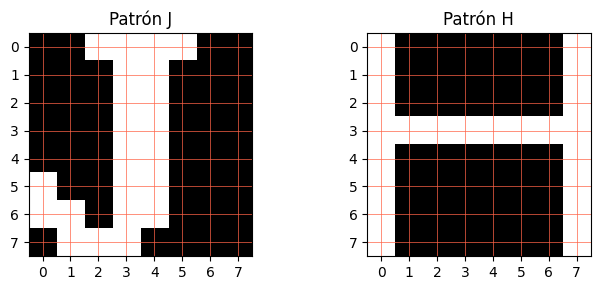

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, pattern, title in zip(axes, [J, H], ["Patrón J", "Patrón H"]):
    ax.imshow(pattern, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.grid(color="tomato", linewidth=0.5)
plt.tight_layout()
plt.show()


## 3. Funciones de la memoria asociativa

Implementaremos cuatro operaciones:

- `softmax`: calcula pesos normalizados de manera estable.
- `update_state`: aplica la regla de actualización obtenida analíticamente.
- `energy`: evalúa la energía \(E(\mathbf q)\) del enunciado.
- `evolve`: itera la red y guarda los estados y las energías.

La convergencia se detectará cuando el cambio máximo entre dos estados consecutivos sea menor que una tolerancia fijada.

In [7]:
def softmax(z):
    """Softmax estable: exp(z - max(z)) normalizado."""
    z = np.asarray(z, dtype=float)
    z_shifted = z - np.max(z)
    weights = np.exp(z_shifted)
    return weights / np.sum(weights)


def pattern_weights(q, X, beta):
    """Peso asignado a cada patrón almacenado."""
    similarities = X @ q
    return softmax(beta * similarities)


def update_state(q, X, beta):
    """Actualización para alpha=1: promedio ponderado de los patrones."""
    weights = pattern_weights(q, X, beta)
    return weights @ X


def energy(q, X, beta):
    """E(q) = 1/2 ||q||^2 - (1/beta) log(sum_mu exp(beta x_mu.q))."""
    similarities = X @ q
    z = beta * similarities
    z_max = np.max(z)
    log_sum_exp = z_max + np.log(np.sum(np.exp(z - z_max)))
    return 0.5 * np.dot(q, q) - log_sum_exp / beta


def evolve(q0, X, beta, max_iter=300, tol=1e-8):
    """Evoluciona la red y devuelve estados, energías y condición de parada."""
    q = np.asarray(q0, dtype=float).copy()
    states = [q.copy()]
    energies = [energy(q, X, beta)]
    converged = False

    for iteration in range(1, max_iter + 1):
        q_new = update_state(q, X, beta)
        states.append(q_new.copy())
        energies.append(energy(q_new, X, beta))

        if np.max(np.abs(q_new - q)) < tol:
            q = q_new
            converged = True
            break

        q = q_new

    return {
        "states": np.array(states),
        "energies": np.array(energies),
        "iterations": len(states) - 1,
        "converged": converged,
    }


def to_binary(q):
    """Convierte el estado continuo a {-1,+1}; cero se asigna a +1."""
    return np.where(q >= 0, 1.0, -1.0)


def recovery_percentage(q, target):
    """Porcentaje de componentes cuyo signo coincide con el patrón objetivo."""
    return 100 * np.mean(to_binary(q) == target)


La perturbación se realiza invirtiendo aleatoriamente el signo de un porcentaje de los píxeles. Por ejemplo, un píxel \(+1\) pasa a \(-1\), y uno \(-1\) pasa a \(+1\).



In [8]:
def perturb_pattern(pattern, percentage, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    original = np.asarray(pattern, dtype=float).ravel()
    n_pixels = original.size
    n_flip = int(round(percentage / 100 * n_pixels))

    flipped_indices = rng.choice(n_pixels, size=n_flip, replace=False)
    perturbed = original.copy()
    perturbed[flipped_indices] *= -1

    return perturbed, flipped_indices


def show_triplet(original, perturbed, final_continuous, title="Recuperación"):
    final_binary = to_binary(final_continuous)
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))

    images = [
        (original.reshape(8, 8), "Original"),
        (perturbed.reshape(8, 8), "Perturbado"),
        (final_continuous.reshape(8, 8), "Estado final continuo"),
        (final_binary.reshape(8, 8), "Estado final binario"),
    ]

    for ax, (image, label) in zip(axes, images):
        ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
        ax.set_title(label, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


Elegimos uno de los patrones almacenados, lo perturbamos y usamos el estado perturbado como condición inicial $\mathbf q^{(0)}$.

Para comenzar, seleccionamos J y usamos un 20 % de píxeles invertidos. El valor de $\beta$ se puede modificar en esta celda.

Patrón objetivo: J
Píxeles invertidos: 13 de 64
Iteraciones: 2
Convergencia alcanzada: True
Recuperación final: 100.00 %


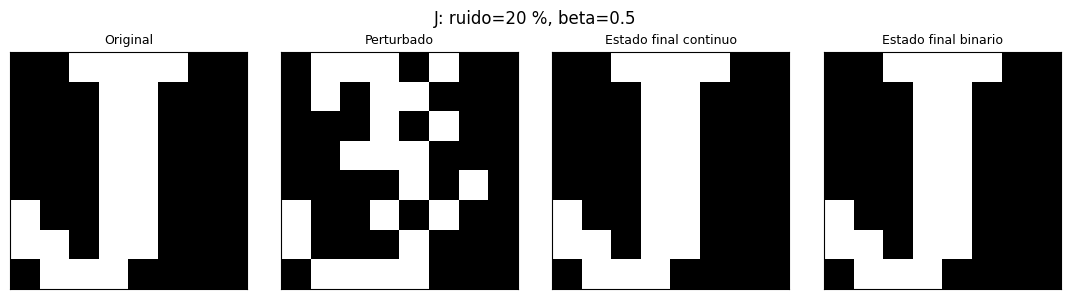

In [9]:
target_name = "J"
noise_percentage = 20
beta_example = 0.5
max_iterations = 300

target = J.ravel() if target_name == "J" else H.ravel()
q0, flipped = perturb_pattern(target, noise_percentage, RNG)

result = evolve(q0, X, beta=beta_example,
                max_iter=max_iterations, tol=1e-8)

q_final = result["states"][-1]

print(f"Patrón objetivo: {target_name}")
print(f"Píxeles invertidos: {len(flipped)} de 64")
print(f"Iteraciones: {result['iterations']}")
print(f"Convergencia alcanzada: {result['converged']}")
print(f"Recuperación final: {recovery_percentage(q_final, target):.2f} %")

show_triplet(target, q0, q_final,
             title=f"{target_name}: ruido={noise_percentage} %, beta={beta_example}")


## Evolución del estado y de la energía

Para ver cómo cambian la energía y la distancia entre estados sucesivos. La distancia se define como

$d_t=\max_i\left|q_i^{(t+1)}-q_i^{(t)}\right|$

Esta cantidad permite visualizar cuándo el estado deja prácticamente de cambiar.

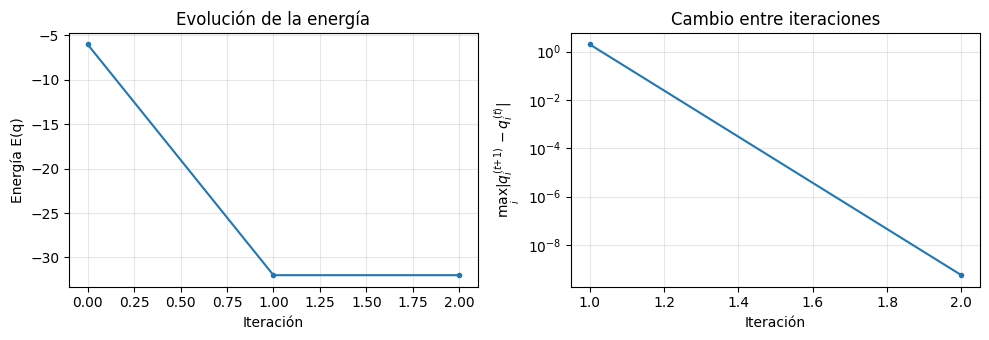

In [10]:
states = result["states"]
energies = result["energies"]

if len(states) > 1:
    changes = np.max(np.abs(np.diff(states, axis=0)), axis=1)
else:
    changes = np.array([])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(np.arange(len(energies)), energies, marker=".")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("Energía E(q)")
axes[0].set_title("Evolución de la energía")
axes[0].grid(alpha=0.3)

axes[1].semilogy(np.arange(1, len(changes) + 1),
                 np.maximum(changes, 1e-16), marker=".")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel(r"$\max_i |q_i^{(t+1)}-q_i^{(t)}|$")
axes[1].set_title("Cambio entre iteraciones")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


el algoritmo implementa una iteración de punto fijo derivada del descenso del gradiente con $\alpha=1$. No debemos asumir de antemano que la energía disminuirá estrictamente en cada paso para cualquier $\beta$ y cualquier condición inicial.

# Calidad de recuperación frente al porcentaje de perturbación

Una sola perturbación aleatoria no es suficiente para evaluar el comportamiento de la memoria. Para cada porcentaje realizaremos varias pruebas independientes.

En cada prueba:
1. Se parte del patrón J o H.
2. Se invierte aleatoriamente el porcentaje indicado de píxeles.
3. Se evoluciona la red.
4. Se calcula el porcentaje de píxeles cuyo signo coincide con el patrón original.

Reportaremos el promedio y la desviación estándar de la recuperación.

In [16]:
def noise_experiment(pattern, X, beta, percentages,
                     repetitions=30, max_iter=300, seed=1234):
    rng = np.random.default_rng(seed)
    records = []

    for percentage in percentages:
        scores = []
        iterations = []
        convergence_flags = []

        for _ in range(repetitions):
            q0_trial, _ = perturb_pattern(pattern, percentage, rng)
            result_trial = evolve(q0_trial, X, beta,
                                  max_iter=max_iter, tol=1e-8)
            q_trial = result_trial["states"][-1]

            scores.append(recovery_percentage(q_trial, pattern))
            iterations.append(result_trial["iterations"])
            convergence_flags.append(result_trial["converged"])

        records.append({
            "Ruido (%)": percentage,
            "Recuperación media (%)": np.mean(scores),
            "Desviación (%)": np.std(scores),
            "Iteraciones medias": np.mean(iterations),
            "Convergencia (%)": 100 * np.mean(convergence_flags),
        })

    return pd.DataFrame(records)


percentages = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
beta_noise = 0.5
repetitions = 30

results_J = noise_experiment(J.ravel(), X, beta_noise, percentages,
                              repetitions=repetitions, seed=10)
results_H = noise_experiment(H.ravel(), X, beta_noise, percentages,
                              repetitions=repetitions, seed=20)

display(results_J.round(2))
display(results_H.round(2))


,Ruido (%),Recuperación media (%),Desviación (%),Iteraciones medias,Convergencia (%)
0,0,100.00,0.00,1.00,100.0
1,5,100.00,0.00,2.00,100.0
2,10,100.00,0.00,2.00,100.0
3,15,100.00,0.00,2.00,100.0
4,20,100.00,0.00,2.27,100.0
5,25,100.00,0.00,2.67,100.0
6,30,100.00,0.00,2.87,100.0
7,35,99.06,5.05,2.97,100.0
8,40,98.12,7.02,2.93,100.0
9,45,85.94,20.22,2.77,100.0


,Ruido (%),Recuperación media (%),Desviación (%),Iteraciones medias,Convergencia (%)
0,0,100.00,0.00,1.00,100.0
1,5,100.00,0.00,2.00,100.0
2,10,100.00,0.00,2.00,100.0
3,15,100.00,0.00,2.13,100.0
4,20,100.00,0.00,2.23,100.0
5,25,100.00,0.00,2.47,100.0
6,30,100.00,0.00,2.83,100.0
7,35,100.00,0.00,3.00,100.0
8,40,96.25,12.01,2.93,100.0
9,45,85.00,23.79,2.93,100.0


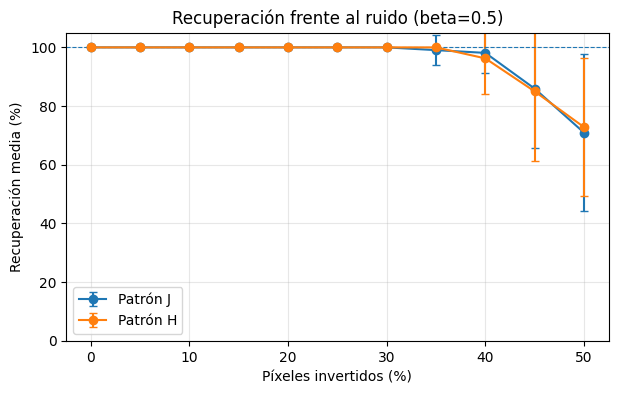

In [17]:
plt.figure(figsize=(7, 4))
for name, df in [("J", results_J), ("H", results_H)]:
    plt.errorbar(df["Ruido (%)"], df["Recuperación media (%)"],
                 yerr=df["Desviación (%)"], marker="o", capsize=3,
                 label=f"Patrón {name}")

plt.axhline(100, linewidth=0.8, linestyle="--")
plt.xlabel("Píxeles invertidos (%)")
plt.ylabel("Recuperación media (%)")
plt.title(f"Recuperación frente al ruido (beta={beta_noise})")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Influencia de $\beta$ en la evolución y el estado final

Ahora fijamos un patrón y una perturbación inicial, y repetimos la evolución con distintos valores de $\beta$. Así comparamos los efectos de cambiar la selectividad sin cambiar la condición inicial.

Recordemos que:
$
\frac{\exp(\beta\,\mathbf x_\mu\cdot\mathbf q)}
{\sum_\nu \exp(\beta\,\mathbf x_\nu\cdot\mathbf q)}.
$


In [18]:
# Se fija una misma condición inicial para que la comparación sea justa.
beta_target = J.ravel()
q0_beta, _ = perturb_pattern(beta_target, 20,
                             np.random.default_rng(321))

beta_values = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]
beta_records = []
beta_runs = {}

for beta_value in beta_values:
    run = evolve(q0_beta, X, beta_value,
                 max_iter=300, tol=1e-8)
    beta_runs[beta_value] = run
    q_end = run["states"][-1]

    final_weights = pattern_weights(q_end, X, beta_value)
    beta_records.append({
        "Beta": beta_value,
        "Recuperación J (%)": recovery_percentage(q_end, J.ravel()),
        "Peso final de J": final_weights[0],
        "Peso final de H": final_weights[1],
        "Energía inicial": run["energies"][0],
        "Energía final": run["energies"][-1],
        "Iteraciones": run["iterations"],
        "Convergió": run["converged"],
    })

beta_table = pd.DataFrame(beta_records)
display(beta_table.round(5))


,Beta,Recuperación J (%),Peso final de J,Peso final de H,Energía inicial,Energía final,Iteraciones,Convergió
0,0.01,100.0,0.50000,0.50000,-52.65731,-83.31472,19,True
1,0.05,100.0,0.96636,0.03364,-7.43289,-32.60292,13,True
2,0.10,100.0,0.99925,0.00075,-6.05501,-32.00750,6,True
3,0.25,100.0,1.00000,0.00000,-6.00001,-32.00000,3,True
4,0.50,100.0,1.00000,0.00000,-6.00000,-32.00000,2,True
5,1.00,100.0,1.00000,0.00000,-6.00000,-32.00000,2,True
6,2.00,100.0,1.00000,0.00000,-6.00000,-32.00000,2,True
7,5.00,100.0,1.00000,0.00000,-6.00000,-32.00000,2,True
8,10.00,100.0,1.00000,0.00000,-6.00000,-32.00000,2,True


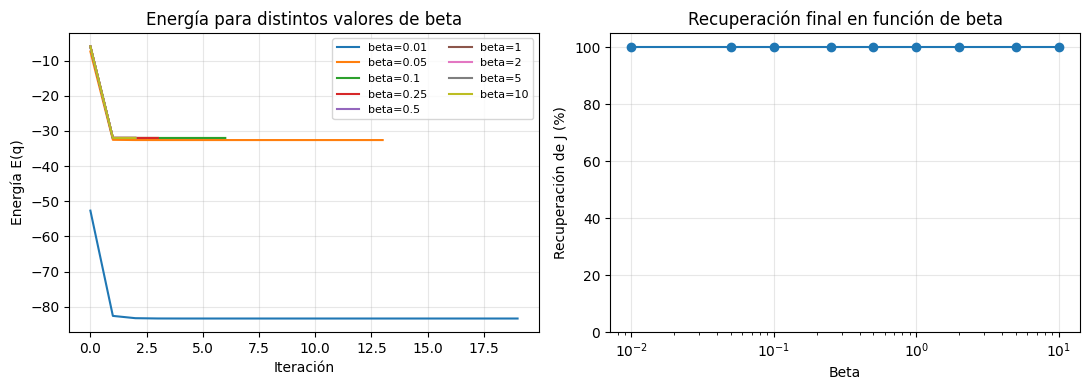

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for beta_value, run in beta_runs.items():
    axes[0].plot(run["energies"], label=f"beta={beta_value:g}")

axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("Energía E(q)")
axes[0].set_title("Energía para distintos valores de beta")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, ncol=2)

axes[1].semilogx(beta_table["Beta"],
                 beta_table["Recuperación J (%)"], marker="o")
axes[1].set_xlabel("Beta")
axes[1].set_ylabel("Recuperación de J (%)")
axes[1].set_title("Recuperación final en función de beta")
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Estados finales para distintos valores de $\beta$

Esta figura permite comparar directamente los estados continuos y sus versiones binarias. El mismo estado inicial se utiliza para todos los valores de $\beta$

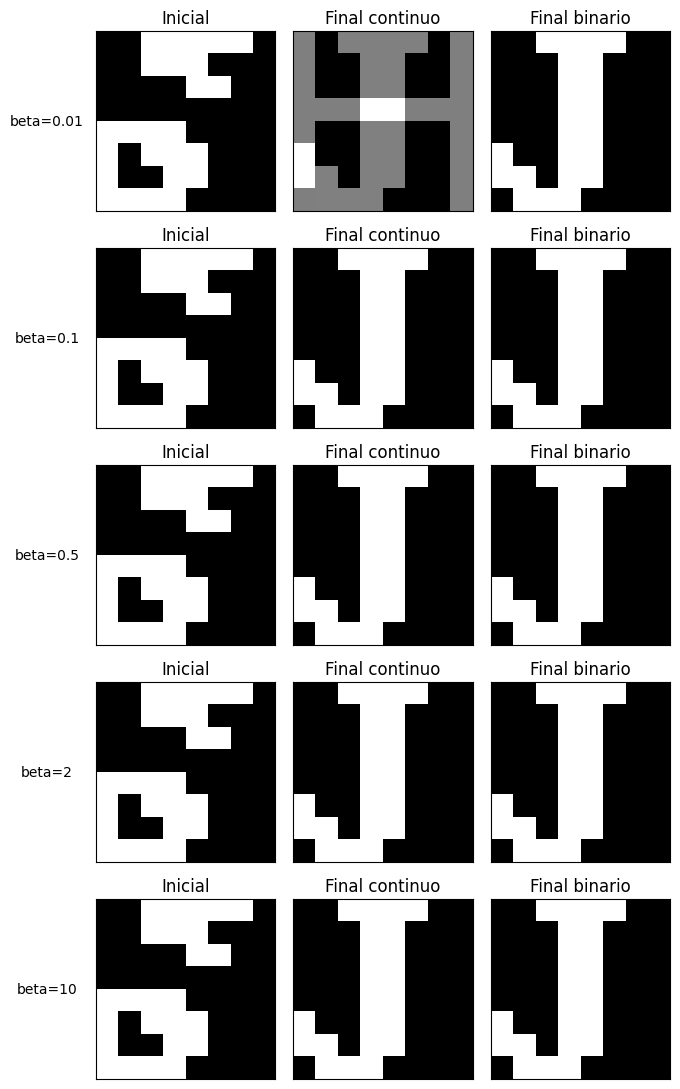

In [15]:
selected_betas = [0.01, 0.1, 0.5, 2.0, 10.0]
fig, axes = plt.subplots(len(selected_betas), 3,
                         figsize=(7, 2.2 * len(selected_betas)))

for row, beta_value in enumerate(selected_betas):
    q_end = beta_runs[beta_value]["states"][-1]
    axes[row, 0].imshow(q0_beta.reshape(8, 8), cmap="gray",
                        vmin=-1, vmax=1)
    axes[row, 1].imshow(q_end.reshape(8, 8), cmap="gray",
                        vmin=-1, vmax=1)
    axes[row, 2].imshow(to_binary(q_end).reshape(8, 8), cmap="gray",
                        vmin=-1, vmax=1)

    axes[row, 0].set_ylabel(f"beta={beta_value:g}", rotation=0,
                            labelpad=35, va="center")
    for col, title in enumerate(["Inicial", "Final continuo", "Final binario"]):
        axes[row, col].set_title(title)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

plt.tight_layout()
plt.show()

Al aumentar $\beta$, la red se vuelve más selectiva y concentra su actualización en el patrón con mayor similitud. Es importante señalar que la recuperación binaria del 100 % para $\beta=0.01$ no significa que la red haya seleccionado exclusivamente J: sus pesos finales indican que ambos patrones contribuyen por igual. Por tanto, para interpretar la recuperación conviene observar tanto el estado binario como los pesos de los patrones.

En los experimentos realizados, la energía disminuyó durante las iteraciones y posteriormente se estabilizó. Por ejemplo, para $\beta=0.5$, pasó de aproximadamente -6 a -32, alcanzando la estabilidad en dos iteraciones. Para valores pequeños de $\beta$, la evolución fue más gradual y requirió más iteraciones. Esto muestra que el parámetro también modifica la rapidez con la que se alcanza el estado estable en estos experimentos.